# Nghiên cứu: Note bảo toàn vốn trên cổ phiếu FPT

**Câu hỏi nghiên cứu.** Mình (người phát hành) bán cho khách một hợp đồng: khách đóng `N`, sau `T` tháng nhận lại
ít nhất một phần vốn được bảo toàn, cộng một phần mức tăng của FPT. Khách không bán lại được hợp đồng trên thị trường.

1. Với lãi suất và vol của FPT, **điều khoản nào** (participation, cap, mức bảo toàn) là khả thi?
2. Nếu bán đều đặn cho cả một tập khách từ 2010 tới nay và delta-hedge hằng ngày, **người bán lãi/lỗ ra sao** — từng note và cả book?
3. **Khách được gì** — so với gửi tiết kiệm và so với tự mua FPT?

**Payoff khi đáo hạn**

$$\text{Khách nhận} = N\Big[\text{Protection} + \text{Participation}\times\min\big(\max(R,0),\ \text{Cap}\big)\Big],\qquad R = \frac{S_T}{S_0}-1$$

**Người bán tách hợp đồng làm hai phần**: một bond leg $N\cdot\text{Protection}\cdot e^{-rT}$ (để trả gốc) và một
vị thế **short** call spread (strike $S_0$ và $S_0(1+\text{Cap})$) cho khách. Phần còn lại $N - \text{bond} - \text{option}$ là margin của mình.

Toàn bộ mô phỏng nằm trong `note_backtest.py` (cùng thư mục); notebook này gọi lại các hàm của nó.

## 0. Thiết lập

In [1]:
import math
from types import SimpleNamespace

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FixedLocator, FuncFormatter, MaxNLocator, NullLocator, PercentFormatter

import note_backtest as nb

# palette: categorical slots in fixed order + recessive inks
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID, REF = "#0b0b0b", "#52514e", "#e6e5e0", "#8a8983"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlesize": 11.5,
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10, "figure.dpi": 110,
})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


def pct_axis(ax, axis="y", decimals=0):
    fmt = PercentFormatter(1.0, decimals=decimals)
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)


def label_end(ax, x, y, text, color, dy=0):
    # direct label at the end of a line, text in ink (identity carried by the colored marker)
    ax.plot([x], [y], "o", color=color, ms=5, mec="white", mew=1.5, zorder=5)
    ax.annotate(text, (x, y), xytext=(6, dy), textcoords="offset points", va="center", fontsize=9, color=INK)

**Tham số nghiên cứu** — đổi ở đây rồi Run All.

In [2]:
SYMBOL       = "FPT"
RATE         = 0.05      # risk-free rate / funding (năm, liên tục)
MARGIN       = 0.005     # margin của người bán, % notional mỗi note
MATURITY     = 63        # phiên giao dịch (~3 tháng)
LIMIT_LOCK   = True      # kịch trần: lệnh mua hedge không khớp; kịch sàn: lệnh bán không khớp
T2           = True      # cổ phiếu mua hôm nay chỉ bán được từ phiên T+2
SLIPPAGE     = 9.0       # bps mỗi lệnh hedge: nửa spread (FPT ~57k, bước giá 100đ ≈ 17 bps)
EXAMPLE_NOTE = "2025-03-03"

T       = MATURITY / nb.DAYS
DEPOSIT = math.exp(RATE * T) - 1     # gửi tiết kiệm cùng kỳ hạn
df = nb.load_daily(SYMBOL)           # cache data/FPT_1D.csv; nb.load_daily(SYMBOL, refresh=True) để tải lại
vol60 = np.log(df["close"]).diff().rolling(60).std() * math.sqrt(nb.DAYS)
print(f"{SYMBOL}: {len(df)} phiên, {df.time.iat[0].date()} -> {df.time.iat[-1].date()}; "
      f"giá cuối {df.close.iat[-1]:,.0f} VND, vol 60 phiên {vol60.iat[-1]:.1%}; gửi tiết kiệm {MATURITY} phiên = {DEPOSIT:+.2%}")

FPT: 4948 phiên, 2006-12-13 -> 2026-10-22; giá cuối 57,400 VND, vol 60 phiên 27.2%; gửi tiết kiệm 63 phiên = +1.26%


## 1. Dữ liệu: giá và vol của FPT

Không có thị trường option niêm yết trên FPT nên **không có implied vol**. Người bán định giá bằng realized vol
60 phiên gần nhất (chỉ dùng dữ liệu tới ngày bán — không lookahead).

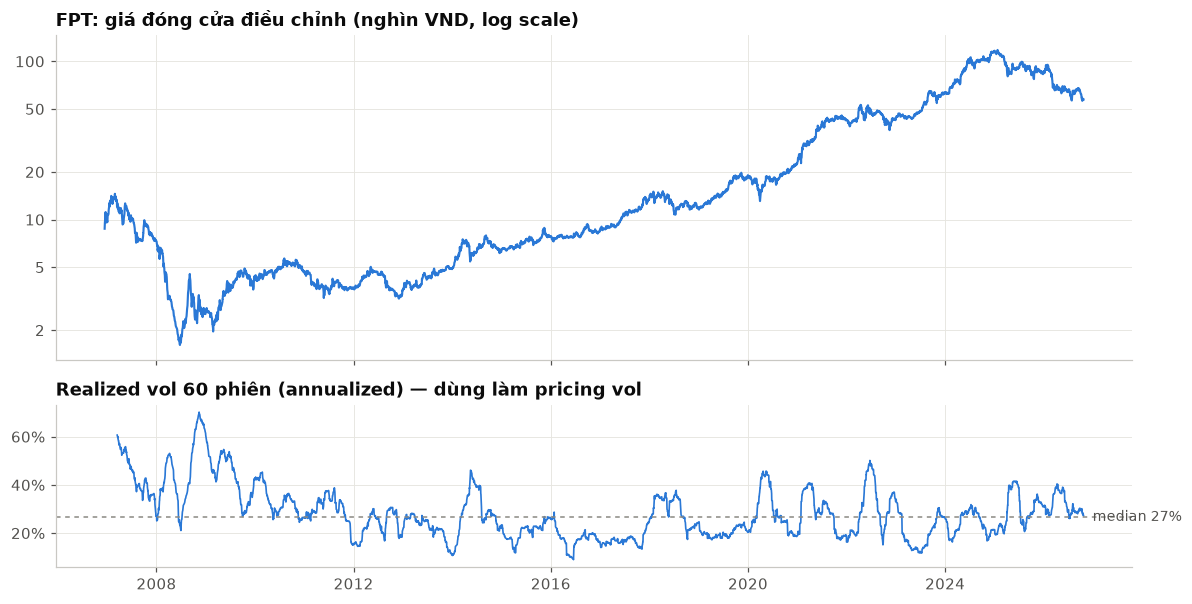

In [3]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True, height_ratios=[2, 1])
a1.plot(df.time, df.close / 1000, color=BLUE, lw=1.4)
a1.set_yscale("log")
a1.yaxis.set_major_locator(FixedLocator([2, 5, 10, 20, 50, 100]))
a1.yaxis.set_minor_locator(NullLocator())
a1.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
a1.set_title(f"{SYMBOL}: giá đóng cửa điều chỉnh (nghìn VND, log scale)")
a2.plot(df.time, vol60, color=BLUE, lw=1.1)
a2.axhline(vol60.median(), color=REF, lw=1, ls=(0, (3, 3)))
a2.annotate(f"median {vol60.median():.0%}", (df.time.iat[-1], vol60.median()), xytext=(6, 0),
            textcoords="offset points", fontsize=9, color=MUTED, va="center")
pct_axis(a2)
a2.set_title("Realized vol 60 phiên (annualized) — dùng làm pricing vol")
fig.tight_layout()
plt.show()

## 2. Sản phẩm: điều khoản khả thi hôm nay

Option budget = $N - N\cdot\text{Protection}\cdot e^{-rT} - \text{margin}$. Với 100% bảo toàn và kỳ hạn 3 tháng,
budget chỉ là tiền lãi của 100 triệu trong 3 tháng (≈1,24 triệu) trừ margin. Cho trước hai trong ba tham số
(participation, cap, margin), tham số còn lại được giải ra.

In [4]:
S0, vol_today = df.close.iat[-1], vol60.iat[-1]
designs_today = {
    "A · 100% bảo toàn, không cap":       dict(protection=1.00),
    "B · 100% bảo toàn, 50% participation": dict(protection=1.00, participation=0.5),
    "C · 98% bảo toàn, 50% participation":  dict(protection=0.98, participation=0.5),
}
rows, terms = [], {}
for name, kw in designs_today.items():
    a = nb.make_args(margin=MARGIN, rate=RATE, maturity_days=MATURITY, **kw)
    p, cap = nb.solve_terms(S0, T, RATE, vol_today, a)
    terms[name] = (a.protection, p, cap)
    rows.append({"thiết kế": name, "protection": f"{a.protection:.0%}", "participation": f"{p:.1%}",
                 "cap (trên mức tăng FPT)": "không" if cap is None else f"{cap:.1%}",
                 "lợi nhuận tối đa của khách": "không giới hạn" if cap is None else f"{a.protection - 1 + p * cap:+.2%}"})
print(f"Báo giá ngày {df.time.iat[-1].date()}: {SYMBOL} {S0:,.0f}, vol {vol_today:.1%}, r {RATE:.0%}, "
      f"margin {MARGIN:.1%}, kỳ hạn {MATURITY} phiên")
pd.DataFrame(rows).set_index("thiết kế")

Báo giá ngày 2026-10-22: FPT 57,400, vol 27.2%, r 5%, margin 0.5%, kỳ hạn 63 phiên


,protection,participation,cap (trên mức tăng FPT),lợi nhuận tối đa của khách
thiết kế,,,,
"A · 100% bảo toàn, không cap",100%,12.3%,không,không giới hạn
"B · 100% bảo toàn, 50% participation",100%,50.0%,3.2%,+1.62%
"C · 98% bảo toàn, 50% participation",98%,50.0%,21.8%,+8.89%


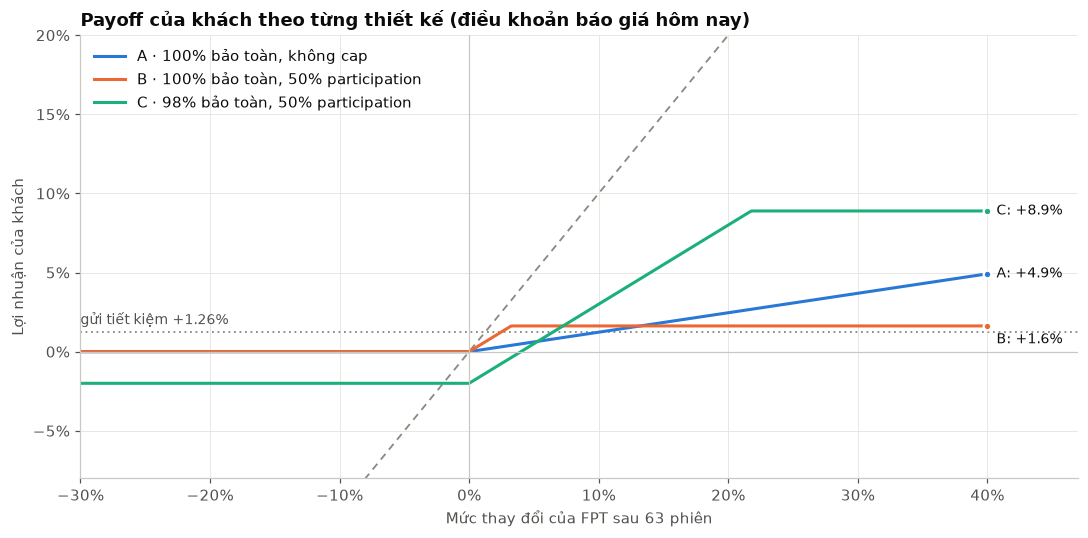

In [5]:
def client_return(R, prot, p, cap):
    return prot - 1 + p * np.clip(R, 0, np.inf if cap is None else cap)

R = np.linspace(-0.30, 0.40, 701)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(R, R, color=REF, lw=1.2, ls=(0, (4, 3)))
ax.axhline(DEPOSIT, color=REF, lw=1.2, ls=(0, (1, 2)))
ax.annotate(f"tự mua {SYMBOL}", (0.33, 0.33), xytext=(-4, 8), textcoords="offset points", fontsize=9, color=MUTED, ha="right")
ax.annotate(f"gửi tiết kiệm {DEPOSIT:+.2%}", (-0.30, DEPOSIT), xytext=(0, 5), textcoords="offset points", fontsize=9, color=MUTED)
for (name, (prot, p, cap)), color, dy in zip(terms.items(), (BLUE, ORANGE, AQUA), (0, -9, 0)):
    y = client_return(R, prot, p, cap)
    ax.plot(R, y, color=color, label=name)
    label_end(ax, R[-1], y[-1], f"{name.split(' ·')[0]}: {y[-1]:+.1%}", color, dy)
ax.axhline(0, color="#c9c8c3", lw=0.8)
ax.axvline(0, color="#c9c8c3", lw=0.8)
pct_axis(ax); pct_axis(ax, "x")
ax.set_ylim(-0.08, 0.20)
ax.set_xlim(-0.30, 0.47)
ax.set_xlabel(f"Mức thay đổi của {SYMBOL} sau {MATURITY} phiên")
ax.set_ylabel("Lợi nhuận của khách")
ax.set_title("Payoff của khách theo từng thiết kế (điều khoản báo giá hôm nay)")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

### Participation phụ thuộc vào gì?

Participation (không cap) $= \dfrac{1-\text{Protection}\cdot e^{-rT}-\text{margin}}{\text{Call ATM}/S_0}$.
Kỳ hạn dài hơn và mức bảo toàn thấp hơn làm budget tăng nhanh hơn giá call; vol cao làm call đắt hơn.
Kỳ hạn 1 tháng với 100% bảo toàn cho participation **âm**: tiền lãi 1 tháng (~0,4%) không đủ trả margin 0,5%.

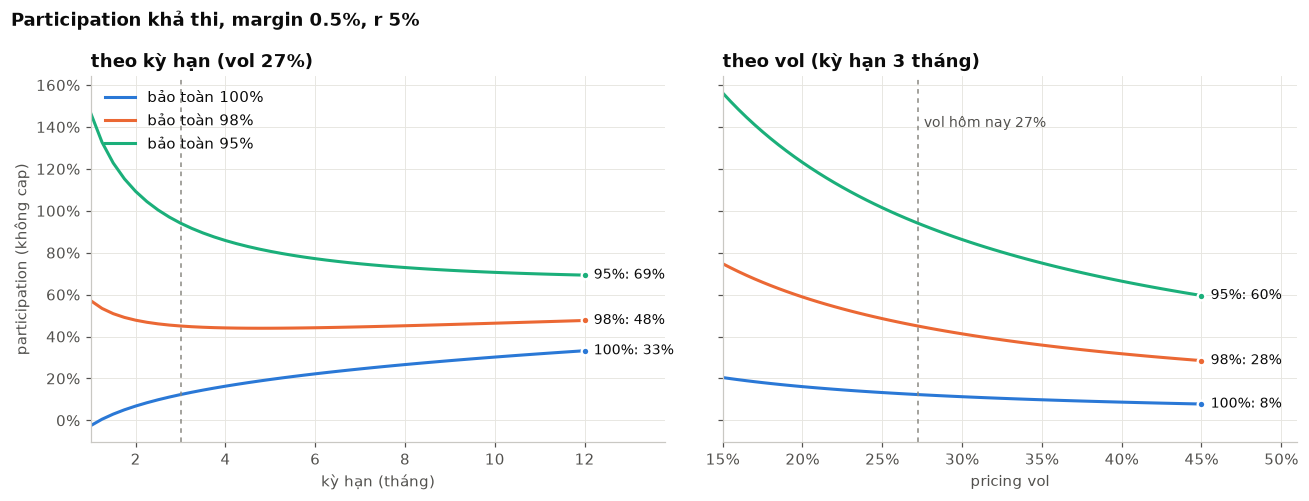

In [6]:
def participation(prot, months, vol, r=RATE, margin=MARGIN):
    Tm = months / 12
    budget = 1 - prot * math.exp(-r * Tm) - margin
    return budget / nb.call(1.0, 1.0, Tm, r, vol)[0]

months = np.arange(1, 12.25, 0.25)
vols = np.linspace(0.15, 0.45, 61)
prots = [(1.00, BLUE), (0.98, ORANGE), (0.95, AQUA)]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for prot, color in prots:
    y1 = [participation(prot, m, vol_today) for m in months]
    a1.plot(months, y1, color=color, label=f"bảo toàn {prot:.0%}")
    label_end(a1, months[-1], y1[-1], f"{prot:.0%}: {y1[-1]:.0%}", color)
    y2 = [participation(prot, 3, v) for v in vols]
    a2.plot(vols, y2, color=color, label=f"bảo toàn {prot:.0%}")
    label_end(a2, vols[-1], y2[-1], f"{prot:.0%}: {y2[-1]:.0%}", color)
a1.axvline(3, color=REF, lw=1, ls=(0, (3, 3)))
a2.axvline(vol_today, color=REF, lw=1, ls=(0, (3, 3)))
a2.annotate(f"vol hôm nay {vol_today:.0%}", (vol_today, 1.4), xytext=(4, 0), textcoords="offset points", fontsize=9, color=MUTED)
a1.set_title(f"theo kỳ hạn (vol {vol_today:.0%})"); a1.set_xlabel("kỳ hạn (tháng)")
a2.set_title("theo vol (kỳ hạn 3 tháng)"); a2.set_xlabel("pricing vol"); pct_axis(a2, "x")
pct_axis(a1); a1.set_ylabel("participation (không cap)")
a1.set_xlim(1, 13.8); a2.set_xlim(0.15, 0.51)
a1.legend(loc="upper left")
fig.suptitle(f"Participation khả thi, margin {MARGIN:.1%}, r {RATE:.0%}", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

## 3. Một note cụ thể: daily ledger

Note bán ngày đầu tiên từ `EXAMPLE_NOTE`, thiết kế mặc định (100% bảo toàn, không cap, participation được giải).
Mỗi phiên người bán mua/bán cổ phiếu để giữ số cổ phiếu = delta của option đã bán (tính theo pricing vol).
Cột `want` là lệnh muốn đặt, `trade` là phần thực sự khớp, `blocked` cho biết lý do không khớp (`limit-up` kịch trần, `limit-down` kịch sàn, `T+2` cổ phiếu chưa về, `carried` bán sau ngày đáo hạn).

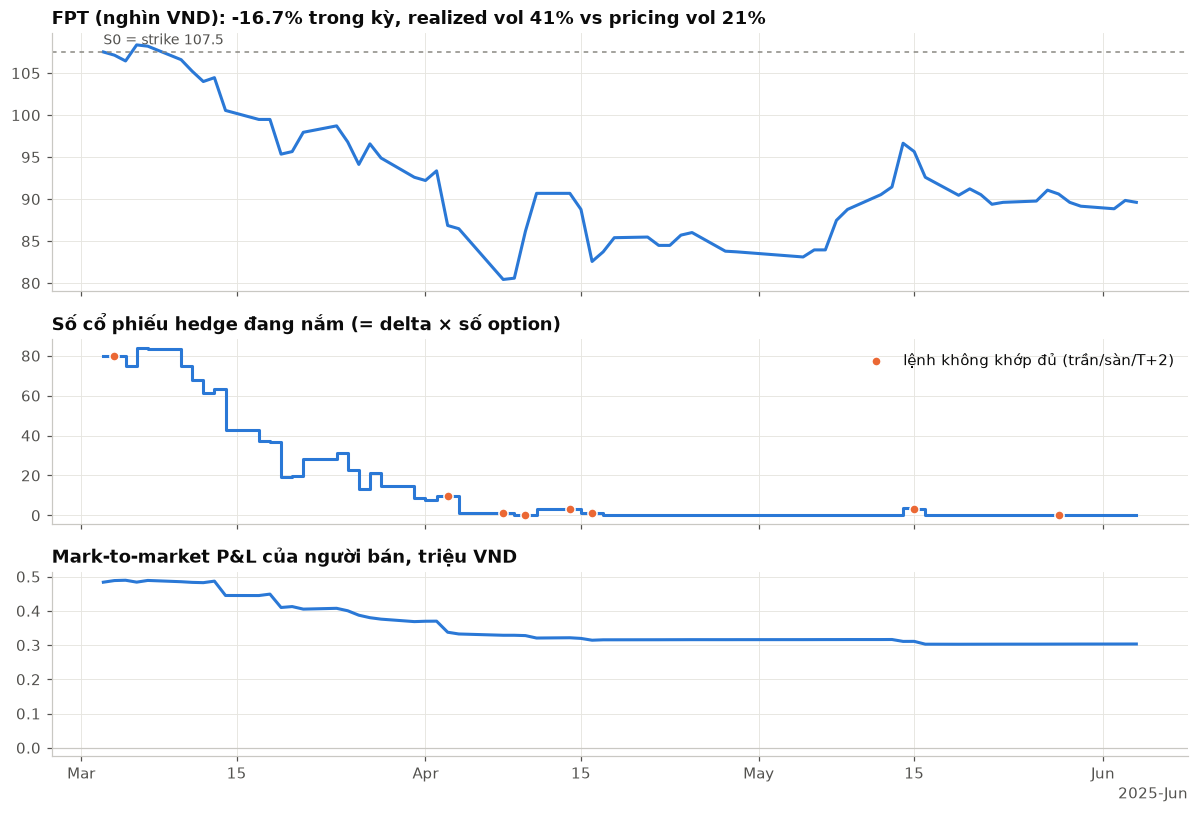

participation 15.18%, option bán cho khách trị giá 0.742tr, margin 0.506tr
khách nhận 100.000tr; người bán: +0.303tr = margin +0.506 + hedge -0.145 − phí 0.059  (không hedge: +1.258tr)
lệnh bị chặn trong note này: 8 ({'T+2': 4, 'limit-down': 3, 'limit-up': 1})


,date,close,days_left,delta,want,trade,blocked,shares,cost,cash,option_value,mtm_pnl
0,2025-03-03,107511.98,63,0.568,80.1,80.1,,80.1,0.016,91.369,0.742,0.484
1,2025-03-04,107129.38,62,0.554,-1.9,-0.0,T+2,80.1,0.000,91.387,0.705,0.488
2,2025-03-05,106440.69,61,0.529,-5.5,-5.5,,74.7,0.002,91.986,0.646,0.489
23,2025-04-03,86851.32,40,0.009,-8.2,0.0,limit-down,9.5,0.000,98.728,0.003,0.338
25,2025-04-08,80423.55,38,0.000,-0.9,0.0,limit-down,1.0,0.000,99.497,0.000,0.329
27,2025-04-10,86162.63,36,0.005,0.6,0.0,limit-up,0.1,0.000,99.613,0.001,0.328
29,2025-04-14,90677.37,34,0.021,-0.2,-0.1,T+2,3.1,0.000,99.375,0.007,0.321
31,2025-04-16,82566.14,32,0.000,-1.3,0.0,limit-down,1.3,0.000,99.572,0.000,0.314
49,2025-05-15,95651.23,14,0.013,-1.8,-0.3,T+2,3.3,0.000,99.721,0.003,0.311
58,2025-05-28,90600.84,5,0.000,-0.0,-0.0,T+2,0.0,0.000,100.204,0.000,0.303


In [7]:
args0 = nb.make_args(rate=RATE, margin=MARGIN, maturity_days=MATURITY, symbol=SYMBOL, slippage_bps=SLIPPAGE, limit_lock=LIMIT_LOCK, t2=T2)
note, led = nb.note_ledger(df, args0, EXAMPLE_NOTE)
led["date"] = pd.to_datetime(led["date"])

fig, (a1, a2, a3) = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True, height_ratios=[1.4, 1, 1])
a1.plot(led.date, led.close / 1000, color=BLUE)
a1.axhline(note["S0"] / 1000, color=REF, lw=1, ls=(0, (3, 3)))
a1.annotate(f"S0 = strike {note['S0'] / 1000:.1f}", (led.date.iat[0], note["S0"] / 1000), xytext=(0, 5),
            textcoords="offset points", fontsize=9, color=MUTED)
a1.set_title(f"{SYMBOL} (nghìn VND): {note['R']:+.1%} trong kỳ, realized vol {note['realized_vol']:.0%} vs pricing vol {note['pricing_vol']:.0%}")
a2.step(led.date, led.shares, where="post", color=BLUE)
blk = led[led.blocked != ""]
if len(blk):
    a2.scatter(blk.date, blk.shares, s=36, color=ORANGE, zorder=5, edgecolors="white", linewidths=1,
               label="lệnh không khớp đủ (trần/sàn/T+2)")
    a2.legend(loc="upper right")
a2.set_title("Số cổ phiếu hedge đang nắm (= delta × số option)")
a3.plot(led.date, led.mtm_pnl, color=BLUE)
a3.axhline(0, color="#c9c8c3", lw=0.8)
a3.set_title("Mark-to-market P&L của người bán, triệu VND")
a3.xaxis.set_major_formatter(mdates.ConciseDateFormatter(mdates.AutoDateLocator()))
fig.tight_layout()
plt.show()

print(f"participation {note['participation']:.2%}, option bán cho khách trị giá {note['option_value']:.3f}tr, margin {note['edge']:.3f}tr")
print(f"khách nhận {note['client_payoff']:.3f}tr; người bán: {note['pnl']:+.3f}tr = margin {note['edge']:+.3f} "
      f"+ hedge {note['hedge_pnl']:+.3f} − phí {note['costs']:.3f}  (không hedge: {note['unhedged_pnl']:+.3f}tr)")
print(f"lệnh bị chặn trong note này: {(led.blocked != '').sum()} "
      f"({led.blocked.value_counts().drop('', errors='ignore').to_dict()})")
pd.concat([led.iloc[:3], led[led.blocked != ""], led.iloc[-2:]]).drop_duplicates("date").round(3)

## 4. Cả tập khách: backtest thiết kế mặc định

Mỗi 5 phiên bán một note mới cho một khách mới (100 triệu), từ 2010. Mỗi note được kiểm tra ledger identity:
P&L tính từ cash account phải khớp với P&L decomposition (margin + hedge − phí) tới 1e-6 VND.

**Chi phí mỗi lệnh hedge:** hoa hồng 10 bps (mua và bán) + thuế bán 10 bps + slippage `SLIPPAGE` bps (nửa bid-ask spread, cả hai chiều). Phí là một dòng riêng trong P&L, slippage được tách riêng bên trong.

In [8]:
notes0, book0 = nb.simulate(df, args0)
args_nh = nb.make_args(rate=RATE, margin=MARGIN, maturity_days=MATURITY, symbol=SYMBOL, slippage_bps=SLIPPAGE, limit_lock=LIMIT_LOCK, t2=T2, hedge=False)

def note_stats(x):
    return pd.Series({"mean": x.mean(), "median": x.median(), "std": x.std(), "% lãi": (x > 0).mean(),
                      "p5": x.quantile(0.05), "tệ nhất": x.min(), "tốt nhất": x.max()})

print(f"{len(notes0)} note, {notes0.start.iat[0]} -> {notes0.start.iat[-1]}; participation median {notes0.participation.median():.1%}")
pd.DataFrame({"có delta-hedge": note_stats(notes0.pnl), "không hedge": note_stats(notes0.unhedged_pnl)}).T.round(2)

826 note, 2010-01-04 -> 2026-07-20; participation median 13.4%


,mean,median,std,% lãi,p5,tệ nhất,tốt nhất
có delta-hedge,0.41,0.42,0.26,0.94,-0.03,-1.13,1.03
không hedge,-0.03,0.60,1.79,0.62,-3.52,-11.07,1.26


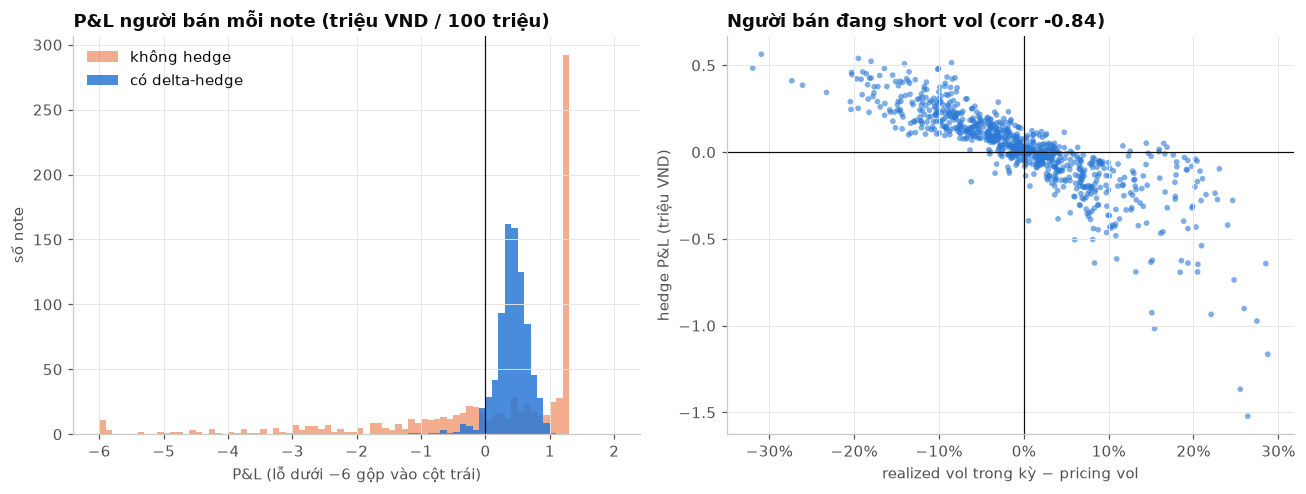

In [9]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6))
bins = np.linspace(-6, 2, 81)
a1.hist(notes0.unhedged_pnl.clip(-6, 2), bins=bins, color=ORANGE, alpha=0.55, label="không hedge")
a1.hist(notes0.pnl, bins=bins, color=BLUE, alpha=0.85, label="có delta-hedge")
a1.axvline(0, color=INK, lw=0.8)
a1.set_title("P&L người bán mỗi note (triệu VND / 100 triệu)")
a1.set_xlabel("P&L (lỗ dưới −6 gộp vào cột trái)")
a1.set_ylabel("số note")
a1.legend(loc="upper left")

gap = notes0.realized_vol - notes0.pricing_vol
a2.scatter(gap, notes0.hedge_pnl, s=14, color=BLUE, alpha=0.6, edgecolors="none")
a2.axhline(0, color=INK, lw=0.8); a2.axvline(0, color=INK, lw=0.8)
pct_axis(a2, "x")
a2.set_xlabel("realized vol trong kỳ − pricing vol")
a2.set_ylabel("hedge P&L (triệu VND)")
a2.set_title(f"Người bán đang short vol (corr {np.corrcoef(gap, notes0.hedge_pnl)[0, 1]:.2f})")
fig.tight_layout()
plt.show()

## 5. Góc nhìn của khách

Mỗi note = một khách. Khách chỉ quan tâm mình nhận được gì so với phương án khác.

lợi nhuận TB / kỳ                      +1.29%
median                                 +0.65%
chỉ nhận lại gốc                          34%
hơn gửi tiết kiệm (+1.26%)                38%
hơn tự mua FPT                            34%
FPT TB / kỳ (tệ nhất)         +5.09% (-30.1%)


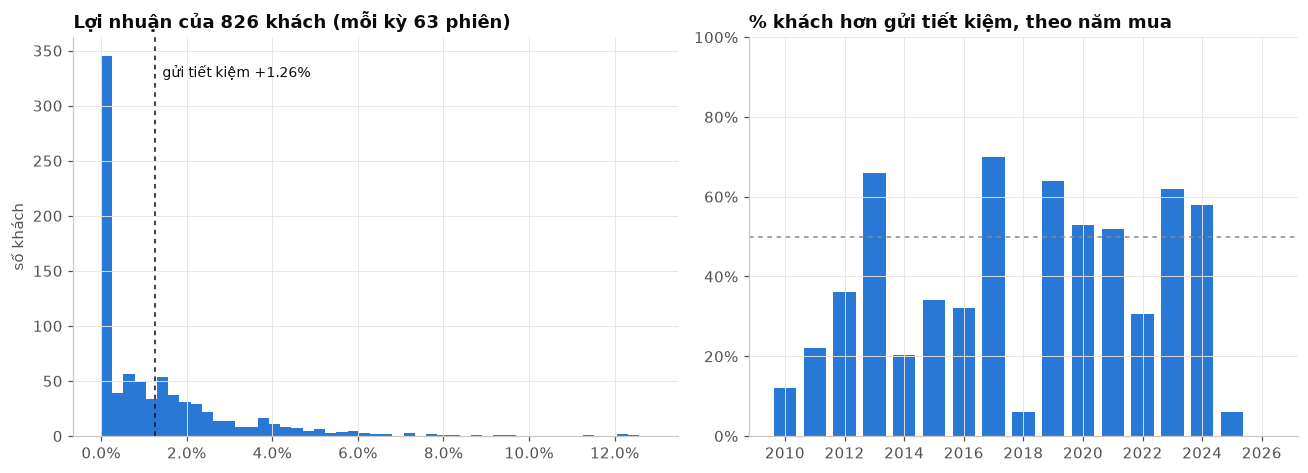

In [10]:
c = notes0.client_return
summary = pd.Series({
    "lợi nhuận TB / kỳ": f"{c.mean():+.2%}",
    "median": f"{c.median():+.2%}",
    "chỉ nhận lại gốc": f"{(c <= 1e-12).mean():.0%}",
    f"hơn gửi tiết kiệm ({DEPOSIT:+.2%})": f"{(c > DEPOSIT).mean():.0%}",
    f"hơn tự mua {SYMBOL}": f"{(c > notes0.R).mean():.0%}",
    f"{SYMBOL} TB / kỳ (tệ nhất)": f"{notes0.R.mean():+.2%} ({notes0.R.min():+.1%})",
})
print(summary.to_string())

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4), width_ratios=[1.1, 1])
a1.hist(c, bins=np.linspace(0, c.max() + 0.005, 50), color=BLUE)
a1.axvline(DEPOSIT, color=INK, lw=1, ls=(0, (3, 3)))
a1.annotate(f"gửi tiết kiệm {DEPOSIT:+.2%}", (DEPOSIT, a1.get_ylim()[1] * 0.9), xytext=(5, 0),
            textcoords="offset points", fontsize=9, color=INK)
pct_axis(a1, "x", 1)
a1.set_title(f"Lợi nhuận của {len(c)} khách (mỗi kỳ {MATURITY} phiên)")
a1.set_ylabel("số khách")

yr = notes0.groupby(pd.to_datetime(notes0.start).dt.year).apply(lambda g: (g.client_return > DEPOSIT).mean())
a2.bar(yr.index, yr.values, color=BLUE, width=0.75)
a2.xaxis.set_major_locator(MaxNLocator(integer=True))
a2.axhline(0.5, color=REF, lw=1, ls=(0, (3, 3)))
pct_axis(a2)
a2.set_ylim(0, 1)
a2.set_title("% khách hơn gửi tiết kiệm, theo năm mua")
fig.tight_layout()
plt.show()

## 6. So sánh các thiết kế: hai phía cùng lúc

Chạy cùng tập khách cho nhiều thiết kế. **Phía khách**: lợi nhuận trung bình và tỉ lệ hơn gửi tiết kiệm.
**Phía người bán**: book gồm mọi note đang sống, mark-to-market hằng ngày, hedge được netting trên cả book.

In [11]:
DESIGNS = {
    "3th · 100%":               dict(),
    "3th · 98%":                dict(protection=0.98),
    "3th · 98% · 50% part.":    dict(protection=0.98, participation=0.5),
    "3th · 95%":                dict(protection=0.95),
    "3th · 95% · margin 1%":    dict(protection=0.95, margin=0.01),
    "6th · 100%":               dict(maturity_days=126),
    "1 năm · 100%":             dict(maturity_days=252),
    "Khách đề xuất 50%/cap 20%": dict(participation=0.5, cap=0.2),
}
runs = {}
for name, kw in DESIGNS.items():
    a = nb.make_args(**{**dict(rate=RATE, margin=MARGIN, maturity_days=MATURITY, symbol=SYMBOL, slippage_bps=SLIPPAGE, limit_lock=LIMIT_LOCK, t2=T2), **kw})
    runs[name] = (a, *nb.simulate(df, a))


def design_row(a, notes, book):
    dep = math.exp(a.rate * a.maturity_days / nb.DAYS) - 1
    daily = book.set_index("time")["pnl"]
    cum = daily.cumsum()
    years = len(book) / nb.DAYS
    cap = notes.cap.median() if notes.cap.notna().any() else np.nan
    return {
        "participation": notes.participation.median(),
        "cap": "—" if np.isnan(cap) else f"{cap:.1%}",
        "khách: LN TB/kỳ": notes.client_return.mean(),
        "khách: LN TB/năm": (1 + notes.client_return.mean()) ** (nb.DAYS / a.maturity_days) - 1,
        "khách: % hơn tiết kiệm": (notes.client_return > dep).mean(),
        "writer: lãi/năm (tr)": cum.iat[-1] / years,
        "writer: % lãi/notional outstanding": cum.iat[-1] / years / book.notional_out.mean(),
        "writer: max drawdown (tr)": (cum - cum.cummax()).min(),
        "writer: tháng tệ nhất (tr)": daily.resample("ME").sum().min(),
        "writer: % tháng lãi": (daily.resample("ME").sum() > 0).mean(),
    }


table = pd.DataFrame({k: design_row(*v) for k, v in runs.items()}).T
fmt = {c: "{:.1%}" for c in ["participation", "khách: LN TB/kỳ", "khách: LN TB/năm", "khách: % hơn tiết kiệm",
                             "writer: % lãi/notional outstanding", "writer: % tháng lãi"]}
fmt.update({c: "{:,.1f}" for c in ["writer: lãi/năm (tr)", "writer: max drawdown (tr)", "writer: tháng tệ nhất (tr)"]})
table.style.format(fmt)

,participation,cap,khách: LN TB/kỳ,khách: LN TB/năm,khách: % hơn tiết kiệm,writer: lãi/năm (tr),writer: % lãi/notional outstanding,writer: max drawdown (tr),writer: tháng tệ nhất (tr),writer: % tháng lãi
3th · 100%,13.4%,—,1.3%,5.3%,37.8%,21.3,1.7%,-5.2,-4.2,95.5%
3th · 98%,48.9%,—,2.7%,11.4%,44.2%,11.2,0.9%,-35.6,-20.6,62.4%
3th · 98% · 50% part.,50.0%,19.3%,2.0%,8.2%,44.7%,22.5,1.8%,-25.1,-17.2,68.3%
3th · 95%,102.2%,—,4.9%,21.0%,45.2%,-4.0,-0.3%,-148.7,-45.3,52.0%
3th · 95% · margin 1%,93.2%,—,4.0%,17.1%,43.8%,23.7,1.9%,-63.9,-39.1,62.9%
6th · 100%,24.1%,—,4.0%,8.2%,48.3%,15.7,0.6%,-38.2,-26.4,78.2%
1 năm · 100%,36.4%,—,10.9%,10.9%,53.4%,-0.6,-0.0%,-133.9,-39.7,62.4%
Khách đề xuất 50%/cap 20%,50.0%,20.0%,3.6%,15.2%,57.7%,-64.0,-5.2%,"-1,067.0",-24.2,8.9%


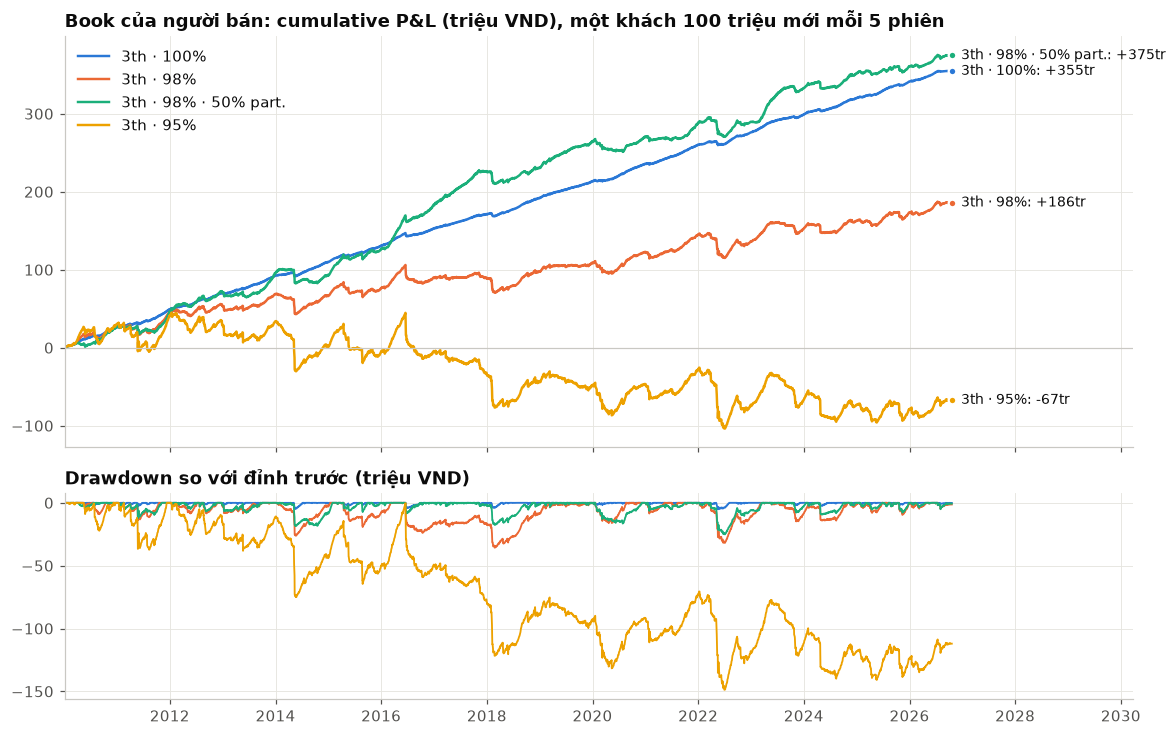

In [12]:
SHOW = [("3th · 100%", BLUE), ("3th · 98%", ORANGE), ("3th · 98% · 50% part.", AQUA), ("3th · 95%", YELLOW)]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6.8), sharex=True, height_ratios=[2, 1])
for name, color in SHOW:
    book = runs[name][2]
    cum = book.pnl.cumsum()
    a1.plot(book.time, cum, color=color, lw=1.6, label=name)
    label_end(a1, book.time.iat[-1], cum.iat[-1], f"{name}: {cum.iat[-1]:+,.0f}tr", color)
    a2.plot(book.time, cum - cum.cummax(), color=color, lw=1.2, label=name)
a1.axhline(0, color="#c9c8c3", lw=0.8)
a1.set_title("Book của người bán: cumulative P&L (triệu VND), một khách 100 triệu mới mỗi 5 phiên")
a2.set_title("Drawdown so với đỉnh trước (triệu VND)")
a1.legend(loc="upper left")
a1.set_xlim(book.time.iat[0], book.time.iat[-1] + pd.Timedelta(days=1250))
a2.xaxis.set_major_formatter(mdates.ConciseDateFormatter(mdates.AutoDateLocator()))
fig.tight_layout()
plt.show()

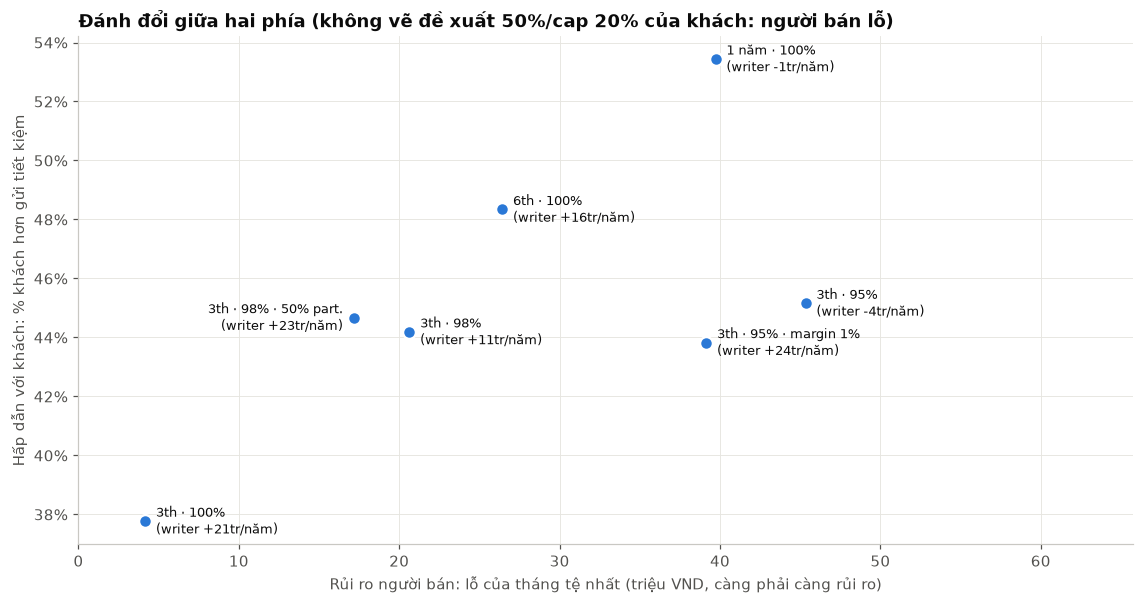

In [13]:
fig, ax = plt.subplots(figsize=(10.5, 5.6))
plot_t = table.drop(index="Khách đề xuất 50%/cap 20%")
ax.scatter(-plot_t["writer: tháng tệ nhất (tr)"], plot_t["khách: % hơn tiết kiệm"], s=70, color=BLUE,
           edgecolors="white", linewidths=1.5, zorder=3)
LEFT = {"3th · 98% · 50% part."}          # labels placed left of the point to avoid collisions
for name, row in plot_t.iterrows():
    left = name in LEFT
    ax.annotate(f"{name}\n(writer {row['writer: lãi/năm (tr)']:+.0f}tr/năm)",
                (-row["writer: tháng tệ nhất (tr)"], row["khách: % hơn tiết kiệm"]),
                xytext=(-7 if left else 7, 0), textcoords="offset points", va="center",
                ha="right" if left else "left", fontsize=8.5, color=INK)
pct_axis(ax)
ax.set_xlabel("Rủi ro người bán: lỗ của tháng tệ nhất (triệu VND, càng phải càng rủi ro)")
ax.set_ylabel("Hấp dẫn với khách: % khách hơn gửi tiết kiệm")
ax.set_xlim(0, plot_t["writer: tháng tệ nhất (tr)"].abs().max() * 1.45)
ax.set_title("Đánh đổi giữa hai phía (không vẽ đề xuất 50%/cap 20% của khách: người bán lỗ)")
fig.tight_layout()
plt.show()

### Chi phí giao dịch: slippage ăn bao nhiêu?

Chạy lại cùng các thiết kế với slippage = 0 để thấy riêng tác động của nửa spread. Participation càng cao thì delta
càng lớn, hedge turnover càng nhiều, nên chi phí tăng theo.

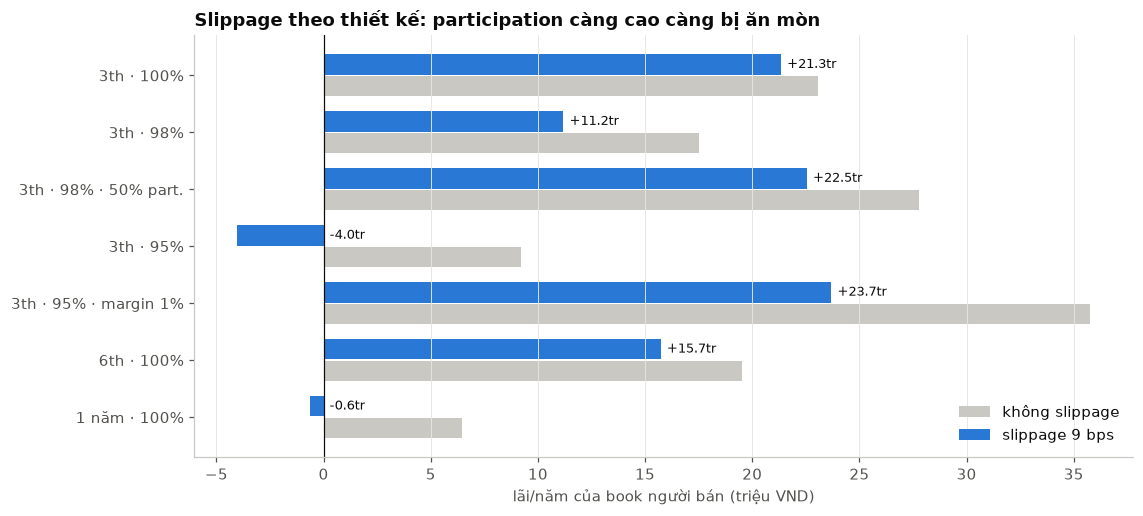

,hedge turnover/note (tr),phí/note (tr),trong đó slippage (tr),"writer lãi/năm, slippage 0","writer lãi/năm, slippage 9bps",chênh lệch/năm
thiết kế,,,,,,
3th · 100%,46.97,0.11,0.04,23.07,21.34,-1.73
3th · 98%,171.95,0.42,0.16,17.53,11.19,-6.34
3th · 98% · 50% part.,149.33,0.36,0.14,27.80,22.55,-5.25
3th · 95%,359.43,0.87,0.33,9.21,-4.04,-13.25
3th · 95% · margin 1%,327.79,0.79,0.30,35.77,23.69,-12.08
6th · 100%,102.93,0.25,0.09,19.52,15.73,-3.78
1 năm · 100%,196.17,0.49,0.18,6.48,-0.64,-7.12
Khách đề xuất 50%/cap 20%,160.14,0.39,0.14,-58.66,-64.04,-5.38


In [14]:
rows = []
for name, (a, notes, book) in runs.items():
    a0 = nb.make_args(**{**{k: v for k, v in vars(a).items() if k != "notional_vnd"}, "slippage_bps": 0.0})
    _, book_0 = nb.simulate(df, a0)
    years = len(book) / nb.DAYS
    rows.append({"thiết kế": name, "hedge turnover/note (tr)": notes.turnover.mean(),
                 "phí/note (tr)": notes.costs.mean(), "trong đó slippage (tr)": notes.slippage.mean(),
                 "writer lãi/năm, slippage 0": book_0.pnl.sum() / years,
                 f"writer lãi/năm, slippage {SLIPPAGE:g}bps": book.pnl.sum() / years})
slip_t = pd.DataFrame(rows).set_index("thiết kế")
slip_t["chênh lệch/năm"] = slip_t.iloc[:, -1] - slip_t.iloc[:, -2]

plot_s = slip_t.drop(index="Khách đề xuất 50%/cap 20%")
y = np.arange(len(plot_s))
fig, ax = plt.subplots(figsize=(10.5, 4.8))
ax.barh(y + 0.19, plot_s.iloc[:, -3], height=0.36, color="#c9c8c3", label="không slippage")
ax.barh(y - 0.19, plot_s.iloc[:, -2], height=0.36, color=BLUE, label=f"slippage {SLIPPAGE:g} bps")
for yi, (v0, v1) in enumerate(zip(plot_s.iloc[:, -3], plot_s.iloc[:, -2])):
    ax.annotate(f"{v1:+.1f}tr", (max(v1, 0), yi - 0.19), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=8.5, color=INK)
ax.set_yticks(y, plot_s.index)
ax.invert_yaxis()
ax.axvline(0, color=INK, lw=0.8)
ax.grid(axis="y", visible=False)
ax.set_xlabel("lãi/năm của book người bán (triệu VND)")
ax.set_title("Slippage theo thiết kế: participation càng cao càng bị ăn mòn")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()
slip_t.round(2)

### Ràng buộc thực tế: kịch trần/sàn và T+2

- **Kịch trần/sàn** (biên độ HOSE 5% tới 14/01/2013, 7% từ 15/01/2013): phiên đóng cửa kịch trần thì lệnh **mua**
  hedge không khớp, kịch sàn thì lệnh **bán** không khớp. Nhận diện xấp xỉ từ OHLC (mức thay đổi giá sát biên độ và giá đóng
  cửa = giá cao/thấp nhất), coi là khoá hoàn toàn (thận trọng).
- **T+2:** cổ phiếu mua ở một phiên chỉ bán được từ phiên thứ hai sau đó. Phần không bán được lúc đáo hạn được bán
  ở phiên sớm nhất cho phép; chênh lệch giá tính vào hedge P&L (`carry`).
- Mỗi note được coi là một tiểu khoản riêng khi áp ràng buộc (thận trọng hơn so với netting trên cả book).

Người bán call luôn cần giao dịch **cùng chiều đám đông**: giá tăng thì delta tăng nên phải mua, đúng lúc kịch trần
không có người bán. Hậu quả phụ thuộc vào việc giá phiên sau tiếp diễn hay đảo chiều.

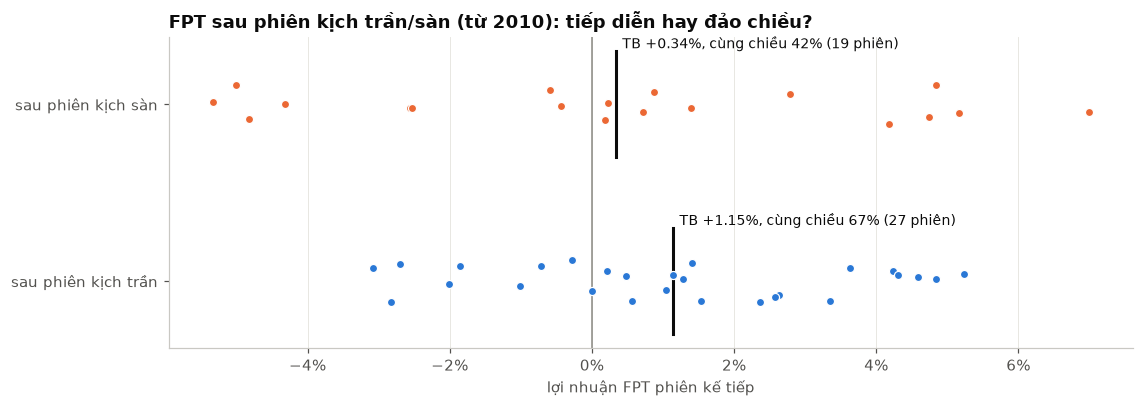

,lãi/năm: không ràng buộc,lãi/năm: trần/sàn + T+2,tháng tệ nhất: không,tháng tệ nhất: có,note tệ nhất: không,note tệ nhất: có,lệnh bị chặn trần/sàn,lệnh bán bị T+2 cắt,carry (tr)
thiết kế,,,,,,,,,
3th · 100%,21.39,21.34,-4.94,-4.16,-0.94,-1.13,545,1028,-0.28
3th · 98%,11.37,11.19,-23.46,-20.64,-4.79,-5.48,545,1033,-1.03
3th · 98% · 50% part.,22.65,22.55,-19.66,-17.15,-3.72,-3.73,517,960,-1.32
3th · 95%,-3.65,-4.04,-51.25,-45.34,-10.56,-12.02,545,1038,-2.14
3th · 95% · margin 1%,24.04,23.69,-44.53,-39.15,-9.08,-10.41,545,1036,-1.96
6th · 100%,15.45,15.73,-29.98,-26.43,-3.21,-3.12,1064,974,0.36
1 năm · 100%,0.13,-0.64,-44.27,-39.73,-6.22,-5.75,2012,902,-0.58
Khách đề xuất 50%/cap 20%,-64.00,-64.04,-24.22,-24.25,-5.33,-5.22,476,1095,0.51


In [15]:
lim = pd.Series(nb.limit_flags(df), index=df.index)
nxt = df.close.pct_change().shift(-1)
since = df.time >= "2010-01-01"
fig, ax = plt.subplots(figsize=(10.5, 3.8))
for k, (f, name, color) in enumerate(((1, "sau phiên kịch trần", BLUE), (-1, "sau phiên kịch sàn", ORANGE))):
    x = nxt[(lim == f) & since].dropna()
    ax.scatter(x, np.full(len(x), k) + np.random.default_rng(k).uniform(-0.12, 0.12, len(x)), s=28,
               color=color, edgecolors="white", linewidths=0.8, zorder=3)
    ax.plot([x.mean()] * 2, [k - 0.3, k + 0.3], color=INK, lw=2)
    ax.annotate(f"TB {x.mean():+.2%}, cùng chiều {(np.sign(x) == f).mean():.0%} ({len(x)} phiên)", (x.mean(), k + 0.3),
                xytext=(4, 2), textcoords="offset points", fontsize=9, color=INK)
ax.axvline(0, color=REF, lw=1)
ax.set_yticks([0, 1], ["sau phiên kịch trần", "sau phiên kịch sàn"])
ax.grid(axis="y", visible=False)
pct_axis(ax, "x")
ax.set_xlabel(f"lợi nhuận {SYMBOL} phiên kế tiếp")
ax.set_title(f"{SYMBOL} sau phiên kịch trần/sàn (từ 2010): tiếp diễn hay đảo chiều?")
fig.tight_layout()
plt.show()

rows = []
for name, (a, notes, book) in runs.items():
    base_kw = {k: v for k, v in vars(a).items() if k != "notional_vnd"}
    notes_off, book_off = nb.simulate(df, nb.make_args(**{**base_kw, "limit_lock": False, "t2": False}))
    years = len(book) / nb.DAYS
    m_on = book.set_index("time").pnl.resample("ME").sum()
    m_off = book_off.set_index("time").pnl.resample("ME").sum()
    rows.append({"thiết kế": name,
                 "lãi/năm: không ràng buộc": book_off.pnl.sum() / years, "lãi/năm: trần/sàn + T+2": book.pnl.sum() / years,
                 "tháng tệ nhất: không": m_off.min(), "tháng tệ nhất: có": m_on.min(),
                 "note tệ nhất: không": notes_off.pnl.min(), "note tệ nhất: có": notes.pnl.min(),
                 "lệnh bị chặn trần/sàn": notes.blocked_limit.sum(), "lệnh bán bị T+2 cắt": notes.blocked_t2.sum(),
                 "carry (tr)": notes.carry_pnl.sum()})
pd.DataFrame(rows).set_index("thiết kế").round(2)

## 7. Kết luận

Số liệu dưới đây là của lần chạy với tham số mặc định: FPT, r 5%, margin 0,5%, slippage 9 bps, có ràng buộc kịch
trần/sàn và T+2, từ 2010, 826 khách. Phía khách không phụ thuộc chi phí và ràng buộc hedge; phía người bán đã trừ
hoa hồng, thuế bán, slippage.

1. **100% bảo toàn, 3 tháng là an toàn cho người bán nhưng kém hấp dẫn với khách.** Budget chỉ ~1,24tr/100tr
   nên participation chỉ ~13%. Người bán lãi +21tr/năm, 96% số tháng có lãi, tháng tệ nhất −4,2tr. Nhưng chỉ 38%
   khách hơn gửi tiết kiệm và 34% chỉ nhận lại gốc.
2. **Đề xuất ban đầu của khách (50% participation, cap 20%, 100% bảo toàn) không khả thi:** người bán lỗ −64tr/năm
   và chỉ 9% số tháng có lãi.
3. **Delta-hedge là bắt buộc.** Std P&L mỗi note giảm từ 1,79tr xuống 0,26tr; note tệ nhất từ −11,1tr còn −1,1tr.
4. **Người bán đang short vol.** Hedge P&L có corr −0,84 với (realized vol − pricing vol). Lỗ tập trung vào
   các cú tăng giá đột ngột sau giai đoạn yên ắng (20/06/2016, tháng 5/2022).
5. **Chi phí giao dịch tăng theo participation.** Slippage 9 bps chỉ lấy ~1,8tr/năm ở thiết kế 100% bảo toàn, nhưng
   ~13,5tr/năm ở thiết kế 95%: thiết kế này chuyển sang **lỗ** (−4tr/năm, max drawdown −149tr).
   Thiết kế 1 năm · 100% cũng về khoảng hoà vốn (−0,6tr/năm).
6. **Kịch trần/sàn và T+2 hầu như không đổi lãi trung bình** (chênh ≤ 0,8tr/năm ở mọi thiết kế) nhưng làm **note
   tệ nhất xấu hơn** (thiết kế 100%: −0,94 → −1,13tr; 95%: −10,6 → −12,0tr). Sau phiên kịch trần, FPT tăng tiếp
   67% số lần (TB +1,15%), nên bị chặn lệnh mua thường bất lợi. Tháng tệ nhất (5/2022) lại bớt lỗ chỉ vì phiên sau
   phiên kịch trần 17/05/2022 FPT giảm 2%: đó là may mắn của lịch sử, không nên coi là lợi ích của ràng buộc.
   FPT chỉ có 46 phiên kịch trần/sàn từ 2010 (1,1%); mã có vol cao hơn sẽ chịu ảnh hưởng nhiều hơn.
7. **Ứng viên cân bằng nhất: 3 tháng, 98% bảo toàn, 50% participation, cap được giải ra** (median ~19%; báo giá
   hôm nay 21,8%, khách tối đa +8,9%). Khách: +2,0%/kỳ (~8%/năm), 45% hơn tiết kiệm. Người bán: +22,5tr/năm,
   tháng tệ nhất −17tr, max drawdown −25tr. Cap làm hedge turnover thấp hơn 98% không cap (149tr so với
   172tr/note), nên sau phí thiết kế không cap chỉ còn +11tr/năm.
8. **95% bảo toàn cần margin cao hơn hẳn:** với margin 1% người bán được +24tr/năm nhưng tháng tệ nhất vẫn −39tr.

**Bước tiếp theo:** hedge P&L attribution (vol / gap / discrete hedging); tính vốn cần giữ và margin tối thiểu cho từng
thiết kế; margin theo năm; upfront fee; chạy trên các mã VN30 khác; chuỗi lãi suất lịch sử thay cho
5% cố định.

## 8. Giới hạn của nghiên cứu

- **Lãi suất cố định** 5% cho cả 2010–2026 (thực tế 2011 trên 10%).
- **Khớp lệnh tại giá đóng cửa** đã biết (thực tế phải đặt lệnh ATC trước khi biết giá). Kịch trần/sàn được nhận diện xấp xỉ từ OHLC, không có order book; T+2 chỉ ràng buộc cổ phiếu, chưa tính thời điểm thanh toán tiền.
- **Giá điều chỉnh cổ tức**: khách được trả trên total return — hơi bất lợi cho người bán so với hợp đồng dùng giá thô.
- **Pricing vol = realized vol quá khứ**; không có implied vol thị trường để so.
- **Slippage cố định theo bps** (9 bps). Thực tế bước giá HOSE cố định theo VND (100đ khi giá ≥ 50.000), nên tính theo % sẽ cao hơn khi giá thấp; giá điều chỉnh cổ tức của những năm đầu không phải giá giao dịch thật nên không dùng để suy ra bước giá được.
- **Margin cố định 0,5%/note** bất kể kỳ hạn → note dài hạn thu margin/năm thấp hơn note 3 tháng.
- **Chỉ một mã (FPT), một kích thước khách**; chưa có upfront fee, chưa có credit risk / rủi ro pháp lý.
- Các note chồng lấn nhau về thời gian → thống kê trên từng note không độc lập; nhìn book (mục 6) để thấy rủi ro thật.